# Titanic Data Set

In [81]:
import pandas as pd

In [82]:
df=pd.read_excel("C:\\Users\\ADMIN\\Downloads\\Titanic-Dataset.xlsx")

In [83]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


# Data Exploration

In [84]:
df.shape

(891, 12)

In [85]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), object(1), str(4)
memory usage: 113.0+ KB


In [86]:
df.dtypes

PassengerId      int64
Survived         int64
Pclass           int64
Name               str
Sex                str
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Cabin              str
Embarked           str
dtype: object

In [87]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


## Data Cleaning

In [88]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [89]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

### Checking Null Values

In [90]:
print(df.duplicated().sum())

0


### Checking Outliers

In [91]:
a=df.select_dtypes(include=['int'])
a.head()

,PassengerId,Survived,Pclass,SibSp,Parch
0,1,0,3,1,0
1,2,1,1,1,0
2,3,1,3,0,0
3,4,1,1,1,0
4,5,0,3,0,0


In [92]:
import seaborn as sns

<Axes: >

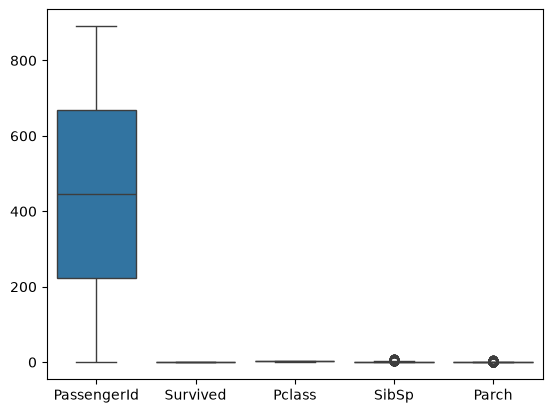

In [93]:
sns.boxplot([a["PassengerId"],a["Survived"],a["Pclass"],a["SibSp"],a["Parch"]])

### Removing Outliers by IQR Method

In [94]:
for i in a:
    q1=a[i].quantile(0.25)
    q2=a[i].quantile(0.50)
    q3=a[i].quantile(0.75)
    IQR=q3-q1
    UW=q3+1.5*IQR
    LW=q1-1.5*IQR
    outliers=((a[i]>UW)|(a[i]<LW))
    print(f"{i}:-",outliers.sum())
    a.loc[outliers,i]=q2
    print(f"after removing outliers in {i}:-",((a[i]>UW)|(a[i]<LW)).sum())

PassengerId:- 0
after removing outliers in PassengerId:- 0
Survived:- 0
after removing outliers in Survived:- 0
Pclass:- 0
after removing outliers in Pclass:- 0
SibSp:- 46
after removing outliers in SibSp:- 0
Parch:- 213
after removing outliers in Parch:- 0


## DATA ANALYSIS

In [95]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [96]:
df.groupby("PassengerId")["Sex"].count()

PassengerId
1      1
2      1
3      1
4      1
5      1
      ..
887    1
888    1
889    1
890    1
891    1
Name: Sex, Length: 891, dtype: int64

In [97]:
df["Age"].value_counts()

Age
24.00    30
22.00    27
18.00    26
28.00    25
19.00    25
         ..
24.50     1
0.67      1
0.42      1
34.50     1
74.00     1
Name: count, Length: 88, dtype: int64

In [98]:
df.groupby("Survived")["Sex"].count()

Survived
0    549
1    342
Name: Sex, dtype: int64

# TITANIC DATASET BY ASHWIN 

In [99]:
import pandas as pd

In [100]:
df=pd.read_excel("C:\\Users\\ADMIN\\Downloads\\Titanic-Dataset.xlsx")

In [101]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [102]:
## DATA EXPLORATION

In [103]:
df.shape

(891, 12)

In [104]:
df.dtypes

PassengerId      int64
Survived         int64
Pclass           int64
Name               str
Sex                str
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Cabin              str
Embarked           str
dtype: object

In [105]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), object(1), str(4)
memory usage: 113.0+ KB


In [106]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


## DATA CLEANING

### NULL VALUES

In [107]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

### REMOVING OR REPLACING NULL VALUES BY MEAN MODE MEDIAN

In [108]:
df=df.drop("Cabin",axis=1)

In [109]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Embarked         2
dtype: int64

In [110]:
df["Age"].skew()

np.float64(0.38910778230082704)

In [111]:
df["Age"]=df["Age"].fillna(df["Age"].mean())

In [112]:
df.isnull().sum()

PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       2
dtype: int64

In [113]:
df["Embarked"]=df["Embarked"].fillna(df["Embarked"].mode()[0])

In [114]:
df.isnull().sum()

PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64

## DUPLICATE

In [115]:
print(df.duplicated().sum())

0


## OUTLIERS ANALYSIS

In [116]:
import numpy as np
a=df.select_dtypes(include=np.number)

In [117]:
for i in a:
    q1=a[i].quantile(0.25)
    q2=a[i].quantile(0.50)
    q3=a[i].quantile(0.75)
    IQR=q3-q1
    UW=q3+1.5*IQR
    LW=q1-1.5*IQR
    outliers=((a[i]>UW)|(a[i]<LW))
    print(outliers.sum())

0
0
0
66
46
213
116


In [118]:
for i in a:
    q1=a[i].quantile(0.25)
    q2=a[i].quantile(0.50)
    q3=a[i].quantile(0.75)
    IQR=q3-q1
    UW=q3+1.5*IQR
    LW=q1-1.5*IQR
    outliers=((a[i]>UW)|(a[i]<LW))
    print(f'{i}:-',outliers.sum())
    a.loc[outliers,i]=q2
    print(((a[i]>UW)|(a[i]<LW)).sum())

PassengerId:- 0
0
Survived:- 0
0
Pclass:- 0
0
Age:- 66
0
SibSp:- 46
0
Parch:- 213
0
Fare:- 116
0


## DATA ANALYSIS

#### How many people survived and how many people died

In [119]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,S


In [136]:
a=df["Survived"].value_counts()

#### Insight 1 - most of the prople died in the incident

### According to age how many survived and died

## BINING

In [121]:
bins=[0,18,40,70]
labels=["child","adult","old"]
df["Agegroup"]=pd.cut(df["Age"],bins=bins,labels=labels)

In [122]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked,Agegroup
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,S,adult
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C,adult
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,S,adult
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,S,adult
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,S,adult


In [140]:
b=df.groupby("Agegroup")["Survived"].mean()*100

#### 2nd Insight, most of the child survived in the incident

### How many males and females survived

In [144]:
c=df.groupby("Sex")["Survived"].mean()*100

#### 74% and 18% females survived in the incident

### 3rd Insight, people suvived according to passenger class 1

In [147]:
d=df.groupby("Pclass")["Survived"].mean()*100

#### Most of the people survived from Passenger Class 1

### 4th Insight,

In [150]:
e=df.groupby("Pclass")["PassengerId"].count()

### Most of the people travelling from Passenger class 3

### 5th Insight

In [155]:
f=df.sort_values(by="Fare",ascending=False)

#### Passengers who spend more money, survived more

## DATA VISUALIZATION

### Creating Dashboard for the given Titanic Dataset

In [133]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked,Agegroup
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,S,adult
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C,adult
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,S,adult
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,S,adult
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,S,adult


In [134]:
import matplotlib.pyplot as plt
import seaborn as sns

<Axes: xlabel='Age', ylabel='Fare'>

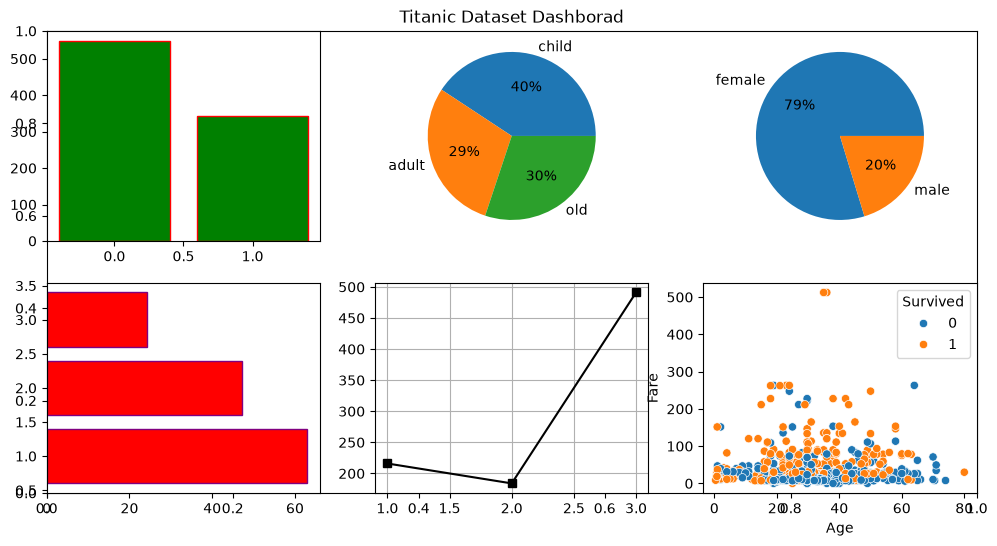

In [157]:
plt.figure(figsize=(12,6))
plt.title("Titanic Dataset Dashborad")
plt.subplot(2,3,1)
plt.bar(a.index,a.values,color="green",edgecolor="red")
plt.subplot(2,3,2)
plt.pie(b.values,labels=b.index,autopct="%1d%%")
plt.subplot(2,3,3)
plt.pie(c.values,labels=c.index,autopct="%1d%%")
plt.subplot(2,3,4)
plt.barh(d.index,d.values,color="red",edgecolor="purple")
plt.subplot(2,3,5)
plt.plot(e.index,e.values,marker="s",color="black")
plt.grid(True)
plt.subplot(2,3,6)
sns.scatterplot(x="Age",y="Fare",hue="Survived",data=df)